In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244630202
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp_env
[学号] 20244630202
[机器指纹] b5fff4197e9c8b2c
[RUN_ID] 20244630202-b5fff4197e9c8b2c


### 实验1：NumPy 数组、数据类型与索引

In [2]:
int_array = np.array([1, 2, 3], dtype=int)
float_array = np.array([1.0, 2.5, 3.5], dtype=float)
bool_array = np.array([True, False, True], dtype=bool)

for name, array in [
    ("整数数组", int_array),
    ("浮点数数组", float_array),
    ("布尔数组", bool_array),
]:
    print(f"{name}: dtype={array.dtype}, shape={array.shape}, ndim={array.ndim}")

整数数组: dtype=int64, shape=(3,), ndim=1
浮点数数组: dtype=float64, shape=(3,), ndim=1
布尔数组: dtype=bool, shape=(3,), ndim=1


#### NumPy数组与Python列表的差别


1. **数据类型（同构 vs 异构）**：NumPy 数组要求所有元素具有统一的 `dtype`（如全是 `int64` 或全是 `float64`）；而 Python 列表是异构容器，可以混合存放不同类型的数据。
2. **内存存储**：NumPy 数组在内存中是一块**连续的原始数据块**，极其紧凑；Python 列表存储的是对象的**指针（引用）**，数据分散且占用内存更大。
3. **运算效率**：NumPy 底层由 C 语言实现，支持**向量化运算**（无需写 for 循环），速度极快；列表进行数学运算通常需要依赖 Python 循环，效率较低。
4. **切片机制**：NumPy 切片默认返回**视图（View）**（共享底层内存，修改切片会影响原数组）；列表切片通常返回**新列表**（拷贝）。
5. **数值精度**：Python 列表中的 `int` 是任意精度（不会溢出）；NumPy 数组的整数是固定位宽（如 `int8`），节省内存但超出范围会溢出。

In [3]:
a = np.arange(12)
array_3x4 = a.reshape(3, 4)
array_2x3x2 = a.reshape(2, 3, 2)
print("形状 (3, 4)：")
print(array_3x4)
print("\n形状 (2, 3, 2)：")
print(array_2x3x2)

形状 (3, 4)：
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2, 3, 2)：
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


改变形状需要满足的条件：元素总数必须保持不变，原数组元素个数应等于新形状各维度大小的乘积。

In [4]:
row_2 = array_3x4[1, :]
cols_1_to_3 = array_3x4[:, 0:3]
greater_than_6 = array_3x4[array_3x4 > 6]

print("第 2 行：", row_2, "形状：", row_2.shape)
print("第 1 至第 3 列：\n", cols_1_to_3, "形状：", cols_1_to_3.shape)
print("大于 6 的元素：", greater_than_6, "形状：", greater_than_6.shape)

第 2 行： [4 5 6 7] 形状： (4,)
第 1 至第 3 列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] 形状： (3, 3)
大于 6 的元素： [ 7  8  9 10 11] 形状： (5,)


In [5]:
numbers = np.arange(10)
# 小于 2 或大于 7
or_mask = (numbers < 2) | (numbers > 7)
selected_or = numbers[or_mask]
# 大于 3 且小于 7
and_mask = (numbers > 3) & (numbers < 7)
selected_and = numbers[and_mask]

print("原数组：", numbers)
print("小于 2 或大于 7：", selected_or)
print("大于 3 且小于 7：", selected_and)
# 使用 np.logical_or() 和 np.logical_and()
mask_or_func = np.logical_or(numbers < 2, numbers > 7)
selected_or_func = numbers[mask_or_func]

mask_and_func = np.logical_and(numbers > 3, numbers < 7)
selected_and_func = numbers[mask_and_func]

print("\n--- 使用 np.logical 函数 ---")
print("np.logical_or (小于 2 或大于 7): ", selected_or_func)
print("np.logical_and (大于 3 且小于 7): ", selected_and_func)

原数组： [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7： [0 1 8 9]
大于 3 且小于 7： [4 5 6]

--- 使用 np.logical 函数 ---
np.logical_or (小于 2 或大于 7):  [0 1 8 9]
np.logical_and (大于 3 且小于 7):  [4 5 6]


In [6]:
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])

print("A * B（逐元素乘法）：\n", matrix_a * matrix_b)
print("np.multiply(A, B)（逐元素乘法）：\n", np.multiply(matrix_a, matrix_b))
print("A @ B（矩阵乘法）：\n", matrix_a @ matrix_b)
print("np.matmul(A, B)（矩阵乘法）：\n", np.matmul(matrix_a, matrix_b))

A * B（逐元素乘法）：
 [[ 5 12]
 [21 32]]
np.multiply(A, B)（逐元素乘法）：
 [[ 5 12]
 [21 32]]
A @ B（矩阵乘法）：
 [[19 22]
 [43 50]]
np.matmul(A, B)（矩阵乘法）：
 [[19 22]
 [43 50]]


#### 逐元素乘法与矩阵乘法

- `*` 和 `np.multiply()` 对应**逐元素乘法**：分别将两个数组中相同位置的元素相乘。本例结果为 `[[5, 12], [21, 32]]`；两个数组形状相同，或符合 NumPy 广播规则时才能进行运算。
- `@` 和 `np.matmul()` 对应**矩阵乘法**：按行与列进行乘加运算。对于形状为 `(m, n)` 和 `(n, p)` 的二维数组，结果形状为 `(m, p)`；内侧维度必须相等。本例结果为 `[[19, 22], [43, 50]]`。

### 实验2：随机抽样、统计与缺失值

In [7]:
rng = np.random.default_rng(42)
simulated_scores = rng.normal(loc=70, scale=10, size=1000)
simulated_scores = np.clip(simulated_scores, 0, 100)

print("模拟成绩统计：")
print("样本数：", simulated_scores.size)
print("最小值：", np.min(simulated_scores))
print("最大值：", np.max(simulated_scores))
print("均值：", np.mean(simulated_scores))
print("标准差：", np.std(simulated_scores))
print("极差：", np.ptp(simulated_scores))

模拟成绩统计：
样本数： 1000
最小值： 33.51587174785217
最大值： 100.0
均值： 69.70929595324685
标准差： 9.881580939490172
极差： 66.48412825214783


In [8]:
# 从 1 到 10 不放回抽取 5 个数：均匀抽样与按数值成比例加权抽样
population = np.arange(1, 11)
uniform_sample = rng.choice(population, size=5, replace=False)
weighted_sample = rng.choice(
    population,
    size=5,
    replace=False,
    p=population / population.sum(),
)
print("均匀抽样：", uniform_sample)
print("按整数大小成比例加权抽样：", weighted_sample)

均匀抽样： [7 2 9 5 4]
按整数大小成比例加权抽样： [3 9 2 6 5]


In [9]:
# permutation 返回新数组，不改变原数组
original_for_permutation = np.arange(1, 11)
print("排列前（原数组）：", original_for_permutation)
permuted_array = rng.permutation(original_for_permutation)
print("排列结果（新数组）：", permuted_array)
print("排列后（原数组仍不变）：", original_for_permutation)

# shuffle 原地打乱传入的数组
array_for_shuffle = np.arange(1, 11)
print("原地打乱前：", array_for_shuffle)
rng.shuffle(array_for_shuffle)
print("原地打乱后：", array_for_shuffle)

排列前（原数组）： [ 1  2  3  4  5  6  7  8  9 10]
排列结果（新数组）： [ 2 10  3  5  1  9  7  8  4  6]
排列后（原数组仍不变）： [ 1  2  3  4  5  6  7  8  9 10]
原地打乱前： [ 1  2  3  4  5  6  7  8  9 10]
原地打乱后： [ 1  2 10  3  6  8  9  4  5  7]


In [10]:
# 将第 10、20、30 个成绩设为缺失值（Python 索引分别为 9、19、29）
simulated_scores[[9, 19, 29]] = np.nan
missing_count = np.count_nonzero(np.isnan(simulated_scores))
print("普通均值：", np.mean(simulated_scores))
print("忽略缺失值后的均值：", np.nanmean(simulated_scores))
print("缺失值个数：", missing_count)

普通均值： nan
忽略缺失值后的均值： 69.71315691233939
缺失值个数： 3


In [11]:
# 内存中的实验数据表，实验 4 可直接使用 scores_df
scores_df = pd.DataFrame({
    "序号": np.arange(1, simulated_scores.size + 1),
    "成绩": simulated_scores,
})
print("实验 4 数据表预览：")
print(scores_df.head(10))
print("数据表形状：", scores_df.shape)

实验 4 数据表预览：
   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
5   6  56.978205
6   7  71.278404
7   8  66.837574
8   9  69.831988
9  10        NaN
数据表形状： (1000, 2)


#### 随机数、缺失值与数据表说明

- `np.random.default_rng(42)` 创建固定种子的随机数生成器，便于重复得到相同结果；`normal()` 按正态分布生成成绩，`clip()` 将每个值限制在 0 到 100 之间。
- `choice(..., replace=False)` 表示不放回抽样。均匀抽样不指定 `p`；加权抽样使用 `p=population / population.sum()`，因此数值越大的整数被抽中的概率越高。
- `rng.permutation(array)` 返回排列后的新数组，原数组保持不变；`rng.shuffle(array)` 则直接修改传入数组。
- 普通 `np.mean()` 遇到 `np.nan` 会得到 `nan`；`np.nanmean()` 忽略缺失值计算均值。许多普通 NumPy 统计函数也会传播 `nan`，可按需使用对应的 `nan` 版本。
- `scores_df` 是保存在当前 Python 内存中的 Pandas DataFrame，含 `序号` 和 `成绩` 两列；没有将数据写入磁盘。

### 实验3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
coefficients = np.array([[3, 1], [1, 2]])
constants = np.array([9, 8])
solution = scipy.linalg.solve(coefficients, constants)

print("方程组解 [x, y]：", solution)
print("代入左侧 A @ 解：", coefficients @ solution)
print("原方程右侧 b：", constants)
print("验证是否相等：", np.allclose(coefficients @ solution, constants))

方程组解 [x, y]： [2. 3.]
代入左侧 A @ 解： [9. 8.]
原方程右侧 b： [9 8]
验证是否相等： True


In [13]:
def root_function(x):
    return x**2 - 2

positive_root_result = scipy.optimize.root(root_function, x0=[1.0])
negative_root_result = scipy.optimize.root(root_function, x0=[-1.0])

for label, result in [("正根", positive_root_result), ("负根", negative_root_result)]:
    root_value = result.x[0]
    function_value = root_function(root_value)
    print(f"{label}：是否成功 = {result.success}，根 = {root_value}")
    print(f"{label}处函数值 = {function_value}，是否接近 0 = {np.isclose(function_value, 0, atol=1e-8)}")

正根：是否成功 = True，根 = 1.4142135623730947
正根处函数值 = -8.881784197001252e-16，是否接近 0 = True
负根：是否成功 = True，根 = -1.4142135623730947
负根处函数值 = -8.881784197001252e-16，是否接近 0 = True


In [14]:
def objective_function(x):
    return x[0]**2 + x[0] + 2

minimize_result = scipy.optimize.minimize(objective_function, x0=[0.0])
analytical_minimum_x = -0.5
analytical_minimum_value = analytical_minimum_x**2 + analytical_minimum_x + 2

print("数值极小点：", minimize_result.x[0])
print("数值最小值：", minimize_result.fun)
print("解析极小点：", analytical_minimum_x)
print("解析最小值：", analytical_minimum_value)

数值极小点： -0.5000000064345924
数值最小值： 1.75
解析极小点： -0.5
解析最小值： 1.75


In [15]:
test_rng = np.random.default_rng(42)
sample_group_1 = test_rng.normal(loc=0, scale=1, size=100)
sample_group_2 = test_rng.normal(loc=1, scale=1, size=100)
ttest_result = scipy.stats.ttest_ind(sample_group_1, sample_group_2)

alpha = 0.05
print("t 统计量：", ttest_result.statistic)
print("p 值：", ttest_result.pvalue)
if ttest_result.pvalue < alpha:
    print("判断：p < 0.05，拒绝两组总体均值相等的原假设，差异具有统计显著性。")
else:
    print("判断：p >= 0.05，不能拒绝两组总体均值相等的原假设，差异不具有统计显著性。")

t 统计量： -8.316637727945347
p 值： 1.441895340492072e-14
判断：p < 0.05，拒绝两组总体均值相等的原假设，差异具有统计显著性。


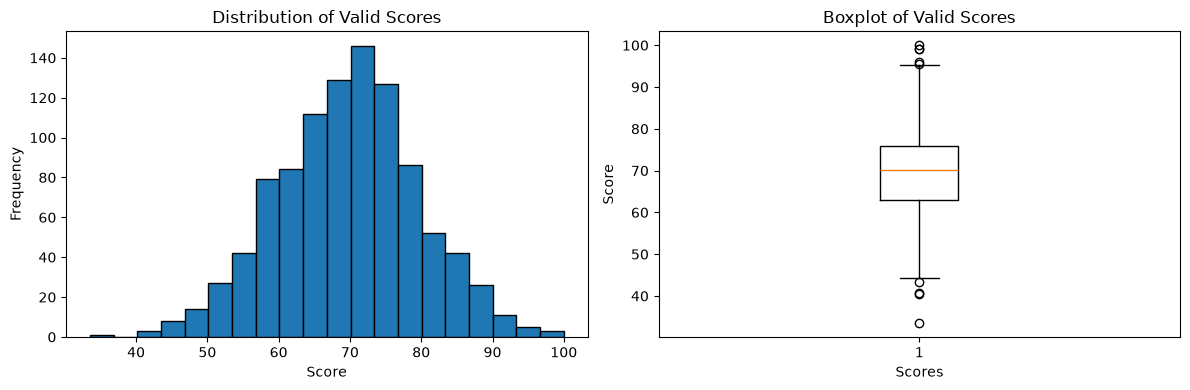

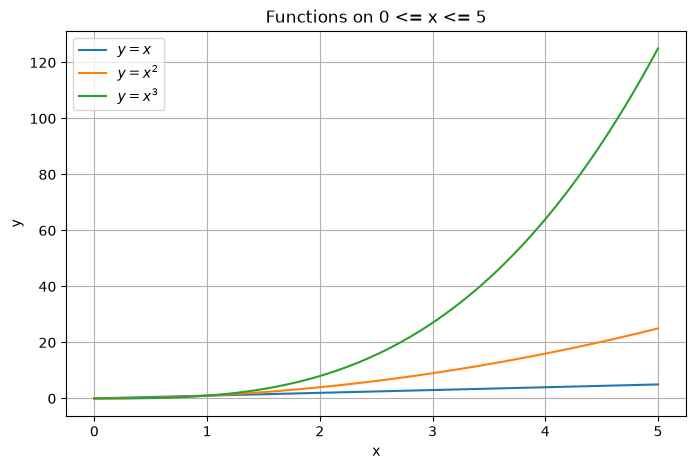

In [16]:
import matplotlib.pyplot as plt

valid_scores = scores_df["成绩"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(valid_scores, bins=20, edgecolor="black")
axes[0].set_title("Distribution of Valid Scores")
axes[0].set_xlabel("Score")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(valid_scores)
axes[1].set_title("Boxplot of Valid Scores")
axes[1].set_xlabel("Scores")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

x_values = np.linspace(0, 5, 200)
plt.figure(figsize=(8, 5))
plt.plot(x_values, x_values, label=r"$y = x$")
plt.plot(x_values, x_values**2, label=r"$y = x^2$")
plt.plot(x_values, x_values**3, label=r"$y = x^3$")
plt.title("Functions on 0 <= x <= 5")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

### 实验4：pandas Series、DataFrame 与内存中的CSV 读写

In [17]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("--- 任务1 ---")
print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("前3行:\n", df.head(3))
print("基本统计信息:\n", df.describe())

--- 任务1 ---
行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前3行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
print("\n--- 任务2 ---")
print("loc读取Carol:\n", df.loc["Carol"])

carol_iloc = df.index.get_loc("Carol")
print("iloc读取Carol:\n", df.iloc[carol_iloc])

filtered_df = df[df["Average"] >= 80]
print("平均分>=80的学生:\n", filtered_df)


--- 任务2 ---
loc读取Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc读取Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分>=80的学生:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
print("\n--- 任务3 ---")
subjects = ["Math", "English", "Python"]
print("列均值(各科平均分):\n", df[subjects].mean(axis=0))
print("行均值:\n", df[subjects].mean(axis=1))


--- 任务3 ---
列均值(各科平均分):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
行均值:
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
print("\n--- 任务4 ---")
df["Highest_Score"] = df[subjects].apply(lambda x: x.max(), axis=1)
print("每人三科最高分:\n", df["Highest_Score"])

agg_result = df[subjects].agg(['min', 'mean', 'max'])
print("\n每科最小值、均值、最大值:\n", agg_result)

df["Rank"] = df["Total"].rank(ascending=False, method='min')
print("\n按总分排名:\n", df[["Total", "Rank"]].sort_values("Rank"))


--- 任务4 ---
每人三科最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Highest_Score, dtype: int64

每科最小值、均值、最大值:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

按总分排名:
        Total  Rank
Name              
Alice    273   1.0
Carol    265   2.0
Eva      257   3.0
Frank    243   4.0
Bob      220   5.0
David    208   6.0


In [21]:
print("\n--- 任务5 ---")
group_stats = df.groupby("Group").agg(
    Count=("Math", "count"), # 人数
    Math_mean=("Math", "mean"),
    English_mean=("English", "mean"),
    Python_mean=("Python", "mean")
)
print("每组人数和三科平均分:\n", group_stats)

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform('mean')
print("\n增加所在组 Python 平均分后的数据:\n", df[["Group", "Python", "Group_Python_Mean"]])


--- 任务5 ---
每组人数和三科平均分:
        Count  Math_mean  English_mean  Python_mean
Group                                             
A          3  79.666667     83.333333    87.000000
B          3  80.000000     78.333333    80.333333

增加所在组 Python 平均分后的数据:
       Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [22]:
print("\n--- 任务6 ---")

retained_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)
filtered_groups_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)
print("保留下来的组和学生:\n", filtered_groups_df)
retained_groups = retained_df["Group"].unique()

print(f"【筛选条件】保留 Python 平均分 >= 80 的组")
print(f"【保留的组】共有 {len(retained_groups)} 个组，分别是: {list(retained_groups)}\n")

for group in retained_groups:
    students = retained_df[retained_df["Group"] == group].index.tolist()
    print(f" -> {group}组 保留的学生: {students}")


--- 任务6 ---
保留下来的组和学生:
       Group  Math  English  Python  Total    Average  Highest_Score  Rank  \
Name                                                                        
Alice     A    88       90      95    273  91.000000             95   1.0   
Bob       A    72       68      80    220  73.333333             80   5.0   
Carol     B    91       85      89    265  88.333333             91   2.0   
David     B    65       73      70    208  69.333333             73   6.0   
Eva       A    79       92      86    257  85.666667             92   3.0   
Frank     B    84       77      82    243  81.000000             84   4.0   

       Group_Python_Mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  
【筛选条件】保留 Python 平均分 >= 80 的组
【保留的组】共有 2 个组，分别是: ['A', 'B']

 -> A组 保留的学生: ['Alice', 'Bob', 'Eva']
 -> B组 保留的学生: ['Carol', 'David', 'Frank']


In [23]:
print("\n--- 任务7 ---")
# 协方差矩阵
cov_matrix = df[subjects].cov()
print("三科成绩协方差矩阵:\n", cov_matrix)

# 皮尔逊相关系数矩阵
corr_matrix = df[subjects].corr()
print("\n三科成绩皮尔逊相关系数矩阵:\n", corr_matrix)



--- 任务7 ---
三科成绩协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

三科成绩皮尔逊相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


#### 协方差与相关系数分析

**选择的科目对：** `Math`（数学）与 `Python`

结合上述计算结果，分析如下：

1. **协方差的含义：** 
   由协方差矩阵可知，`Math` 与 `Python` 的协方差为 **`74.93`**（正数）。这表明这两科成绩呈现**同向变化**趋势，即数学成绩较高的学生，其 Python 成绩往往也较高。

2. **相关系数大小的含义：** 
   由皮尔逊相关系数矩阵可知，`Math` 与 `Python` 的相关系数为 **`0.8848`**。该数值非常接近 1，说明这两科成绩之间存在**极强的正线性相关关系**。

*(补充说明：其他科目如 `English` 与 `Python` 的相关系数为 `0.757`，同样表现为较强的正相关。)*